# Generate source-level connectomes from the ProbConn atlas

---

## 🧪 - Experiment setup
- `src`: Source Space
- `tractogram`: Tractogram
- `ctx`: Cortical Mask
- `t12diff`: T1 subject space to Diffusion space transform
- `ras2tkras`: T1 subject space to FreeSurfer space transform

In [1]:
import mindmap as mm
import numpy as np
import pandas as pd

dm = mm.io.TutoManager("../../config.yml")
sub = "simf10"

src = dm.load(sub, "fwd", desc="sim")["src"]
parc = dm.load(sub, "dseg", space="fs", segmentation="multiconn2022", scale="4")
ras2tkras = dm.load(sub, "ras2tkras")
probcon = dm.load_ref("REF_CON")

## 🧬 - Data Processing

Preprocess atlas.

In [2]:
# convert atlas to binary adjacency matrix
consistency = probcon["matrices"]["consistency"][:,:]
length      = probcon["matrices"]["length"][:,:]
number      = probcon["matrices"]["numbStlines"][:,:]

consistency = np.nan_to_num(consistency)
length      = np.nan_to_num(length)
number      = np.nan_to_num(number)

regions = probcon["header"]["gmcoords"][:]

# Threshold atlas
atlas = np.bitwise_and(
    consistency > 65, 
    length > 0,
)
atlas = np.bitwise_and(
    atlas,
    number > 0,
)
atlas = length * atlas

Upscale connectome from atlas.

In [19]:
# connectivity of white matter tracts
# strength_matrix=consistency modulates sparsity per region pair by the atlas's own
# confidence signal instead of a single uniform value; sparsity_range is a starting
# point -- tune it against the validation metrics further down.
con_atlas = mm.analysis.connectivity.connectome_from_atlas(
    src,
    parc,
    atlas,
    ras2tkras,
    sparsity = 0.14,
    deterministic = True,
)

# connectivity of gray matter tracts
con_geom = mm.analysis.connectivity.connectome_from_geometry(
    src,
    maximum_dist = 22,
    maximum_neigh = 35,
    weights = True,
)

# fuse connectomes
con = con_atlas.copy()
fill_idx = np.argwhere((con_geom > 0) & (con_atlas == 0))
con[fill_idx[:,0], fill_idx[:,1]] = con_geom[fill_idx[:,0], fill_idx[:,1]]

Edge provenance

In [20]:
# Edge provenance: how much of the final connectome is real streamline-derived
# structure vs. the generic local-geometry fallback filling in where
# tractography found nothing.
iu = np.triu_indices(len(con), k=1)
wm_mask = (con_atlas > 0)[iu]
geom_mask = (con_geom > 0)[iu]

wm_only = wm_mask & ~geom_mask
geom_only = geom_mask & ~wm_mask
both = wm_mask & geom_mask

n_total = (wm_mask | geom_mask).sum()
print(f"Total edges in final connectome: {n_total}")
print(f"WM tractography only: {wm_only.sum()} ({wm_only.sum()/n_total*100:.1f} %)")
print(f"Local geometry only:  {geom_only.sum()} ({geom_only.sum()/n_total*100:.1f} %)")
print(f"Both WM and geometry: {both.sum()} ({both.sum()/n_total*100:.1f} %)")

Total edges in final connectome: 219318
WM tractography only: 82285 (37.5 %)
Local geometry only:  118254 (53.9 %)
Both WM and geometry: 18779 (8.6 %)


## 📊 - Visualization
Atlas structural connectome.

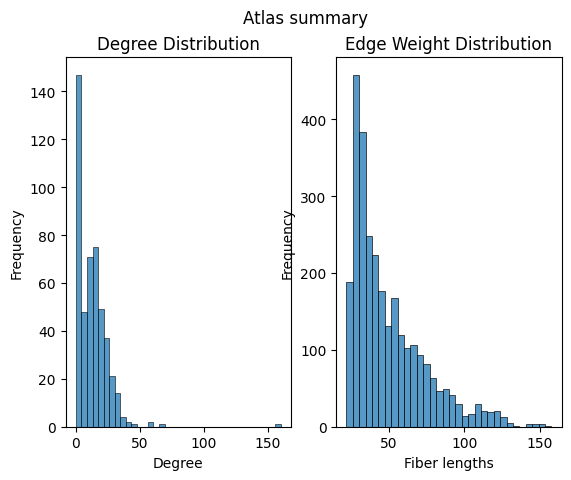

In [21]:
mm.viz.plot_con_summary(atlas, title = "Atlas summary", xlabel="Fiber lengths")

Atlas adjacency matrix.

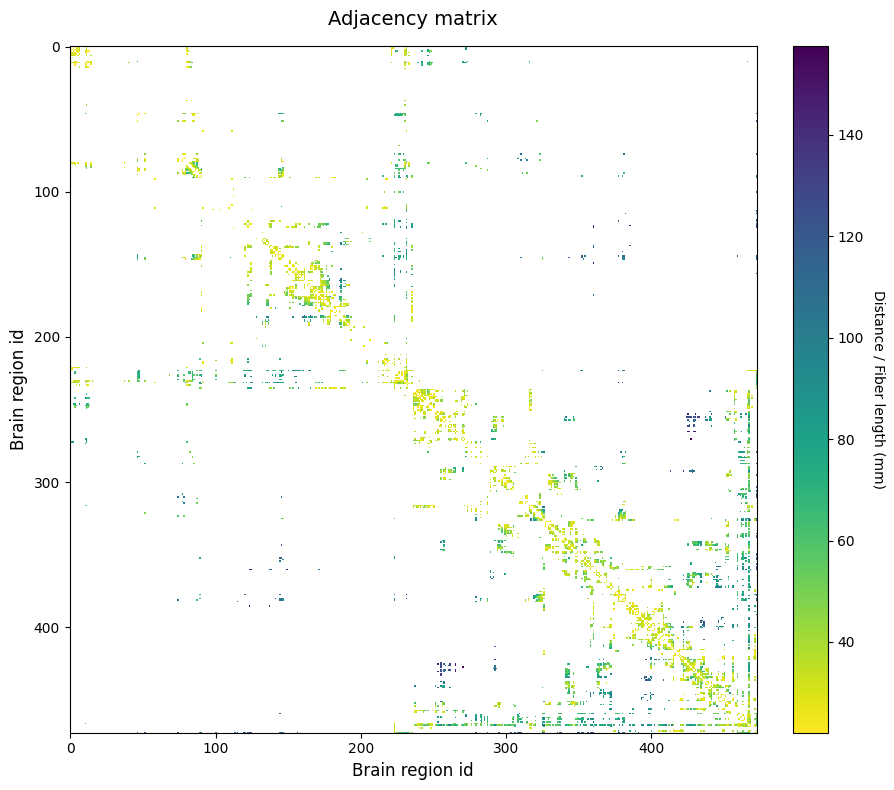

In [22]:
mm.viz.plot_adj_matrix(atlas, clabel="Distance / Fiber length (mm)", xylabel = "Brain region id")

Upscaled connectome summary.

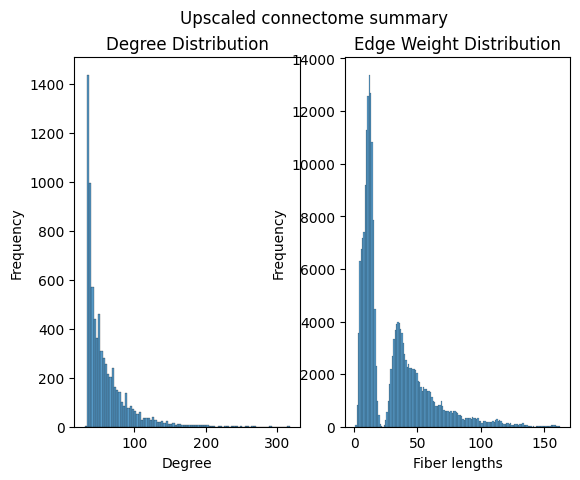

In [23]:
mm.viz.plot_con_summary(con, title = "Upscaled connectome summary", xlabel="Fiber lengths")

Upscaled connectome connectivity matrix.

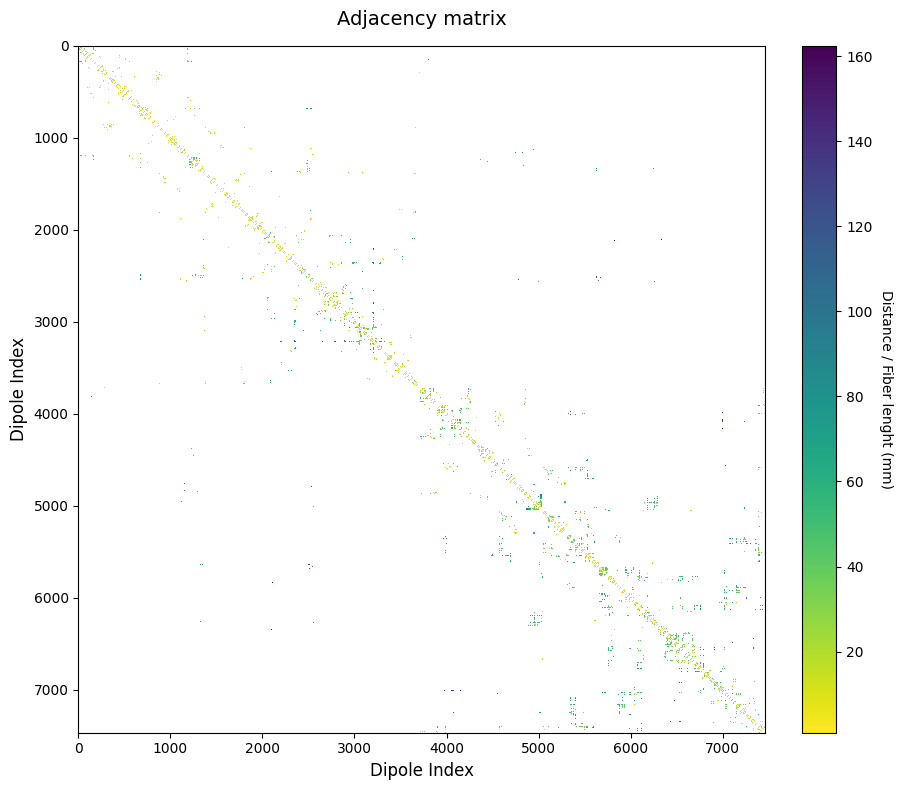

In [24]:
con_viz, _ = mm.analysis.connectivity.order_connectome_by_region(con, src, parc, ras2tkras)
mm.viz.plot_adj_matrix(con_viz, clabel="Distance / Fiber lenght (mm)")


## ✅ - Validation metrics

Quantitative checks, complementing the plots above. Two different questions:
- **correctness**: did the upscaling preserve the atlas it was built from? (`block_conservation`, checked on `con_wm` since GM fusion isn't part of the atlas-upscaling step)
- **realism**: does the dipole-level connectome look like a real structural connectome? (`density`, `small_world_sigma`, `rich_club_curve`, `modularity`, `distance_decay_fit`, `hemispheric_symmetry`)

See `mindmap/analysis/connectivity/process.py`'s module docstring for the literature and target ranges behind each of these.

In [25]:
import matplotlib.pyplot as plt

# Validation metrics on the final (WM + geometry) connectome. n_null=10
# (not the default 20) to keep this tutorial's runtime reasonable at
# dipole resolution -- increase for a less noisy null estimate.
n_dipoles = mm.anatomy.source_space.get_ndipole(src)
print(f"n_dipoles: {n_dipoles}")
print(f"density: {mm.analysis.connectivity.density(con)*100:.3f} %")

sw = mm.analysis.connectivity.small_world_sigma(con, n_null=10, seed=0)
print(f"small-world sigma: {sw['sigma']:.3f}  (C={sw['C']:.3f} vs C_null={sw['C_null']:.3f}, "
      f"L={sw['L']:.3f} vs L_null={sw['L_null']:.3f})")

mod = mm.analysis.connectivity.modularity(con, seed=0)
print(f"modularity: Q={mod['q']:.3f}, {mod['n_communities']} communities")

hemi = mm.analysis.connectivity.hemispheric_symmetry_from_source_space(con, src)
print(f"hemispheric symmetry: r={hemi['r']:.3f}  (mirror-match error: "
      f"mean={hemi['match_dist_mean']:.2f}mm, max={hemi['match_dist_max']:.2f}mm)")

edr = mm.analysis.connectivity.distance_decay_fit_from_source_space(con, src)
print(f"distance-decay (EDR): lambda={edr['lambda_']:.4f} /mm, r2={edr['r2']:.3f}")

n_dipoles: 7465
density: 0.787 %
small-world sigma: 18.951  (C=0.478 vs C_null=0.012, L=5.245 vs L_null=2.585)
modularity: Q=0.758, 12 communities
hemispheric symmetry: r=0.182  (mirror-match error: mean=2.85mm, max=16.36mm)
distance-decay (EDR): lambda=0.1105 /mm, r2=0.489


/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/bct/algorithms/core.py:515: RuntimeWarning: invalid value encountered in scalar divide
  R[k] = Ek[k] / (Nk[k] * (Nk[k] - 1))
/home/nino/Code/mindmap/mindmap/core/metric.py:890: RuntimeWarning: Mean of empty slice
  R_null_mean = np.nanmean(R_null, axis=0)


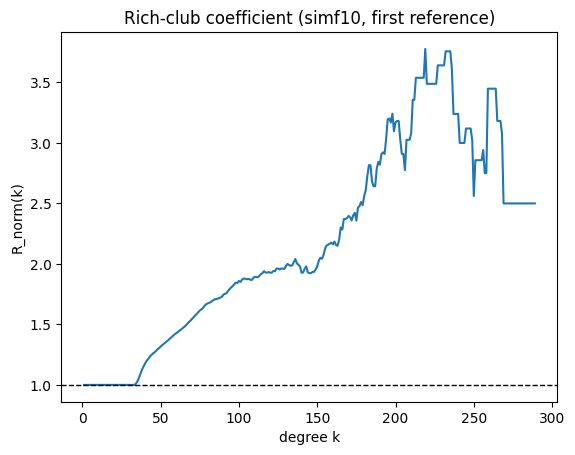

In [26]:
# Rich-club: are high-degree dipoles more densely interconnected than a
# degree-matched null? R_norm(k) > 1 over a range of k is the signature.
rc = mm.analysis.connectivity.rich_club_curve(con, n_null=10, seed=0)

plt.figure()
plt.plot(rc["k"], rc["R_norm"])
plt.axhline(1.0, color="black", linestyle="--", linewidth=1)
plt.xlabel("degree k")
plt.ylabel("R_norm(k)")
plt.title("Rich-club coefficient (simf10, first reference)")
plt.show()

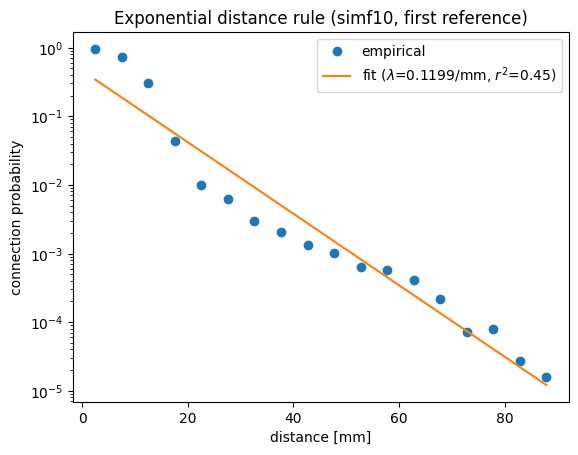

In [18]:
# Exponential distance rule (EDR) fit: connection probability vs. distance.
# Visual check for the log-linear fit computed above.
plt.figure()
valid = np.isfinite(edr["bin_prob"]) & (edr["bin_prob"] > 0)
plt.semilogy(edr["bin_centers"][valid], edr["bin_prob"][valid], "o", label="empirical")

fit = edr["c"] * np.exp(-edr["lambda_"] * edr["bin_centers"])
plt.semilogy(edr["bin_centers"][valid], fit[valid], "-", label=f"fit ($\\lambda$={edr['lambda_']:.4f}/mm, $r^2$={edr['r2']:.2f})")

plt.xlabel("distance [mm]")
plt.ylabel("connection probability")
plt.legend()
plt.title("Exponential distance rule (simf10, first reference)")
plt.show()